# Permutation Test: Did a New Teaching Method Improve Pass Rates?

**Academic project.** A teaching method was tried with one group of 100 students and the pass rate was 15 percentage points higher than in a comparison group of 100. Is that a real effect or random variation?

A permutation test answers this without assuming a normal distribution: pool all 200 outcomes (65 passes, 135 fails), shuffle them into two random groups of 100 many times, and see how often chance alone produces a gap of 15 points or more.

This notebook needs no external data and is fully executed.

In [1]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
IMAGES_DIR = ROOT / 'images'
IMAGES_DIR.mkdir(exist_ok=True)

import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pooled outcomes under H0: 135 did not pass (0), 65 passed (1)
students = pd.Series([0] * 135 + [1] * 65)

def perm_fun(x, na, nb):
    """Randomly split x into groups of size na and nb; return the difference in pass rate (B - A)."""
    n = na + nb
    idx_B = set(random.sample(range(n), nb))
    idx_A = set(range(n)) - idx_B
    return round(x.loc[list(idx_B)].mean() - x.loc[list(idx_A)].mean(), 4)

random.seed(1)  # reproducibility
perm_diffs = [100 * perm_fun(students, 100, 100) for _ in range(1000)]
print(f'Simulations: {len(perm_diffs)} | mean difference: {np.mean(perm_diffs):.2f} pp | std: {np.std(perm_diffs):.2f} pp')

Simulations: 1000 | mean difference: -0.11 pp | std: 6.55 pp


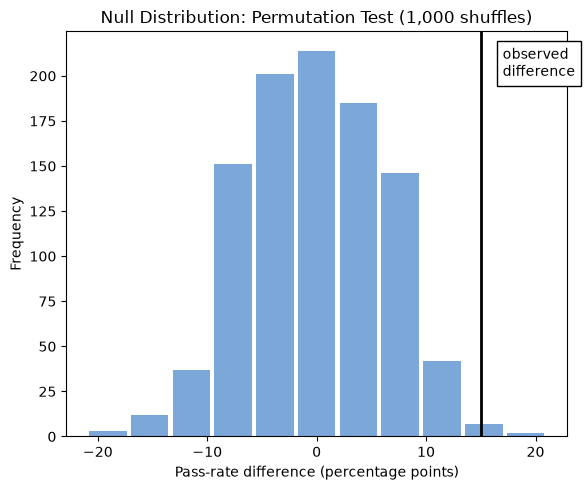

Shuffles with a difference above 15 pp: 3 of 1000
p-value: 0.003
Reject H0 at the 5% level


In [2]:
observed_diff = 15  # percentage points

fig, ax = plt.subplots(figsize=(6, 5))
ax.hist(perm_diffs, bins=11, rwidth=0.9, color='#7BA7D9')
ax.axvline(x=observed_diff, color='black', lw=2)
ax.text(observed_diff + 2, 200, 'observed\ndifference', bbox={'facecolor': 'white'})
ax.set_xlabel('Pass-rate difference (percentage points)')
ax.set_ylabel('Frequency')
ax.set_title('Null Distribution: Permutation Test (1,000 shuffles)')
fig.tight_layout()
fig.savefig(IMAGES_DIR / 'permutation-null-distribution.png', dpi=120)
plt.show()

exceed = sum(diff > observed_diff for diff in perm_diffs)
p_value = np.mean([diff > observed_diff for diff in perm_diffs])
print(f'Shuffles with a difference above {observed_diff} pp: {exceed} of {len(perm_diffs)}')
print(f'p-value: {p_value}')
print('Reject H0 at the 5% level' if p_value < 0.05 else 'Fail to reject H0 at the 5% level')

## Conclusion

Chance alone almost never produces a 15-point gap between two random groups of this size, so the improvement is very unlikely to be noise. The printed p-value above is the share of shuffles that beat the observed difference.

The same course assignment also ran chi-square and ANOVA tests on the store dataset; those are in `01_eda_hypothesis_testing.ipynb`.